# Visual Validation of `tetrahedralize_mask` (Well-Conditioned 3D Shapes)

Visual and geometric verification of the 256-case cubic Delaunay meshing pipeline across multiple masks. 

In [1]:
# %% Imports and tetrahedralization setup
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Line3DCollection, Poly3DCollection
import numpy as np
from nibabel.nifti1 import Nifti1Image

from numpy.typing import NDArray
from lapy import TetMesh

from neuromodes.mesh import tetrahedralize_mask, _mask_to_coords

In [2]:
# %% Plotting and validation helper functions
def extract_tetmesh_topology(
    mesh: TetMesh,
) -> tuple[NDArray[np.int32], NDArray[np.int32], NDArray[np.int32]]:
    """
    Extract unique edges, unique triangular faces, and exterior boundary triangles
    from a tetrahedral mesh.
    """
    t = np.asarray(mesh.t, dtype=np.int32)

    # 6 edges per tetrahedron
    raw_edges = t[:, [[0, 1], [0, 2], [0, 3], [1, 2], [1, 3], [2, 3]]].reshape(-1, 2)
    unique_edges = np.unique(np.sort(raw_edges, axis=1), axis=0)

    # 4 triangular faces per tetrahedron (boundary faces appear exactly once)
    raw_faces = t[:, [[0, 1, 2], [0, 1, 3], [0, 2, 3], [1, 2, 3]]].reshape(-1, 3)
    sorted_faces = np.sort(raw_faces, axis=1)
    unique_faces, unique_idx, counts = np.unique(
        sorted_faces, axis=0, return_index=True, return_counts=True
    )
    boundary_faces = raw_faces[unique_idx[counts == 1]]
    return unique_edges, unique_faces, boundary_faces

def validate_and_plot_tetmesh(
    mask: NDArray[np.bool_],
    title: str,
    affine: NDArray[np.floating] | None = None,
    *,
    elev: float = 24.0,
    azim: float = -38.0,
    vertex_size: float = 14.0,
    edge_alpha: float = 0.35,
    edge_lw: float = 0.6,
    show_boundary_tint: bool = True,
    face_alpha: float = 0.08,
) -> TetMesh:
    """
    Tetrahedralize `mask`, assert geometric invariants, and plot:
      Left : Original active voxel coordinates
      Right: Original vertices overlaid with the 3D TetMesh wireframe
    """
    orig_verts = _mask_to_coords(mask, affine)
    mesh = tetrahedralize_mask(mask, affine=affine)
    verts = np.asarray(mesh.v, dtype=np.float64)
    tets = np.asarray(mesh.t, dtype=np.int32)

    # Verify exact 1-to-1 vertex preservation and positive Jacobian determinants
    assert verts.shape == orig_verts.shape and np.allclose(verts, orig_verts)
    c = verts[tets]
    det6 = np.linalg.det(
        np.stack([c[:, 1] - c[:, 0], c[:, 2] - c[:, 0], c[:, 3] - c[:, 0]], axis=-1)
    )
    assert np.all(det6 > 0), f"Found non-positive Jacobian determinant: min={det6.min()}"

    unique_edges, unique_faces, boundary_faces = extract_tetmesh_topology(mesh)
    V, E, F, T = len(verts), len(unique_edges), len(unique_faces), len(tets)
    euler_3d = V - E + F - T
    total_vol = float(det6.sum() / 6.0)

    # print(
    #     f"{title}: V={V}, E={E}, F={F}, T={T} | "
    #     f"chi(3D)={euler_3d} | min(6*Vol)={det6.min():.4f} | total_vol={total_vol:.2f}"
    # )

    fig, axes = plt.subplots(1, 2, figsize=(13.5, 6.0), subplot_kw={"projection": "3d"})

    # Panel 1: Original vertices
    ax0 = axes[0]
    ax0.scatter(
        orig_verts[:, 0],
        orig_verts[:, 1],
        orig_verts[:, 2],
        c=np.arange(len(orig_verts)),
        cmap="copper",
        s=vertex_size,
        alpha=0.9,
        depthshade=True,
    )
    ax0.set_title(f"Original Active Vertices (V = {V})", fontsize=10.5, pad=6)

    # Panel 2: Original vertices + TetMesh wireframe
    ax1 = axes[1]
    ax1.scatter(
        verts[:, 0],
        verts[:, 1],
        verts[:, 2],
        c=np.arange(len(verts)),
        cmap="copper",
        s=vertex_size * 0.7,
        alpha=0.85,
        zorder=4,
        label="Original vertices",
    )

    if show_boundary_tint and len(boundary_faces) > 0:
        surf = Poly3DCollection(
            verts[boundary_faces],
            facecolors="#000000",
            edgecolors="none",
            alpha=face_alpha,
        )
        ax1.add_collection3d(surf)

    segments = verts[unique_edges]  # (E, 2, 3)
    wireframe = Line3DCollection(
        segments,
        colors="#000000",
        linewidths=edge_lw,
        alpha=edge_alpha,
    )
    ax1.add_collection3d(wireframe)
    ax1.set_title(f"TetMesh (V = {V}, T = {T}, E = {E})", fontsize=10.5, pad=6)

    # Equal physical aspect ratio across both axes
    mins = verts.min(axis=0)
    maxs = verts.max(axis=0)
    spans = np.maximum(maxs - mins, 1e-6)
    pad = 0.08 * spans.max()
    for ax in axes:
        ax.set_xlim(mins[0] - pad, maxs[0] + pad)
        ax.set_ylim(mins[1] - pad, maxs[1] + pad)
        ax.set_zlim(mins[2] - pad, maxs[2] + pad)
        ax.set_box_aspect(spans + 2 * pad)
        ax.view_init(elev=elev, azim=azim)
        ax.set_xlabel("X", fontsize=8.5, labelpad=2)
        ax.set_ylabel("Y", fontsize=8.5, labelpad=2)
        ax.set_zlabel("Z", fontsize=8.5, labelpad=2)
        ax.tick_params(labelsize=7.5)

    fig.suptitle(
        f"{title}  |  V={V}, T={T}, chi={euler_3d}, Vol={total_vol:.2f}",
        fontsize=12,
        fontweight="bold",
        y=0.98,
    )
    plt.tight_layout()
    plt.show()
    return mesh


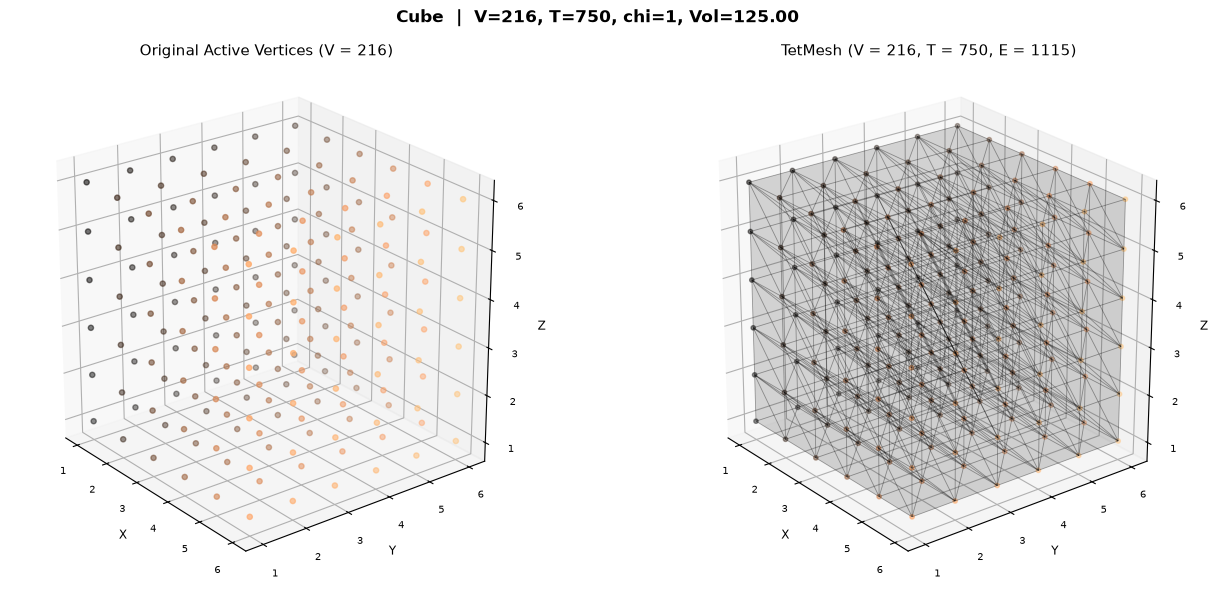

In [3]:
title = 'Cube'

mask = np.zeros((8, 8, 8), dtype=bool)
mask[1:7, 1:7, 1:7] = True  # 6x6x6 vertices = 5x5x5 = 125 unit cubes -> 750 tets

mesh = validate_and_plot_tetmesh(mask, title=title)

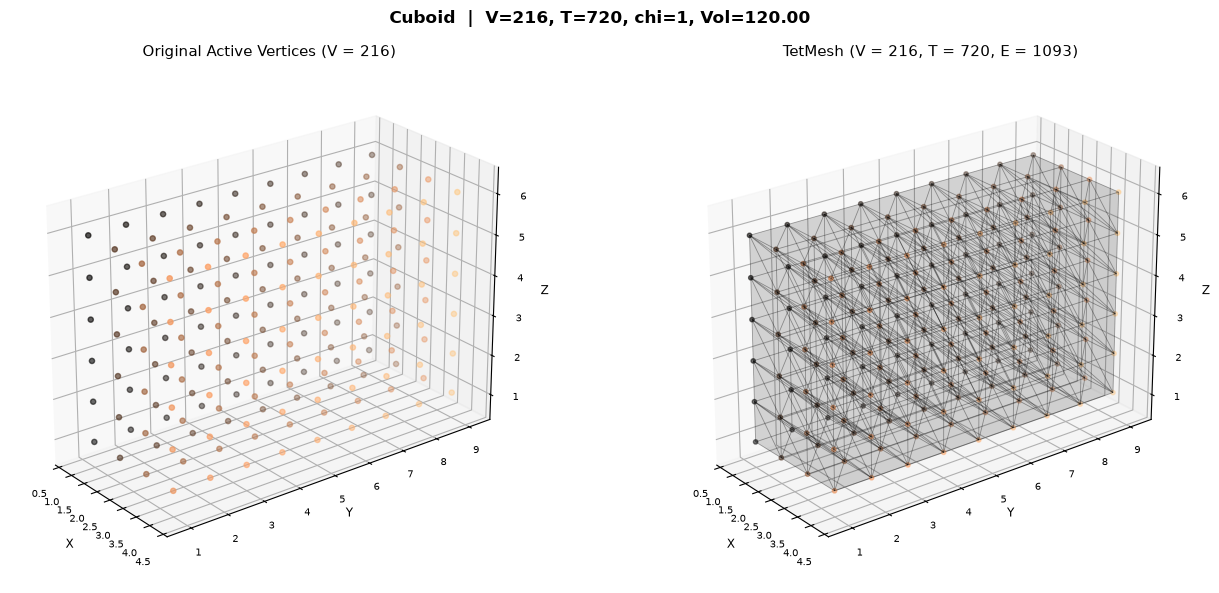

In [4]:
title = 'Cuboid'

mask = np.zeros((7, 11, 8), dtype=bool)
mask[1:5, 1:10, 1:7] = True  # 4x9x6 vertices = 3x8x5 = 120 unit cubes -> 720 tets

affine_las = np.array(
    [
        [-0.8, 0.0, 0.0, 12.0],
        [0.0, 1.2, 0.0, -6.0],
        [0.0, 0.0, 1.8, 3.0],
        [0.0, 0.0, 0.0, 1.0],
    ],
    dtype=np.float64,
)

mesh = validate_and_plot_tetmesh(mask, title=title)


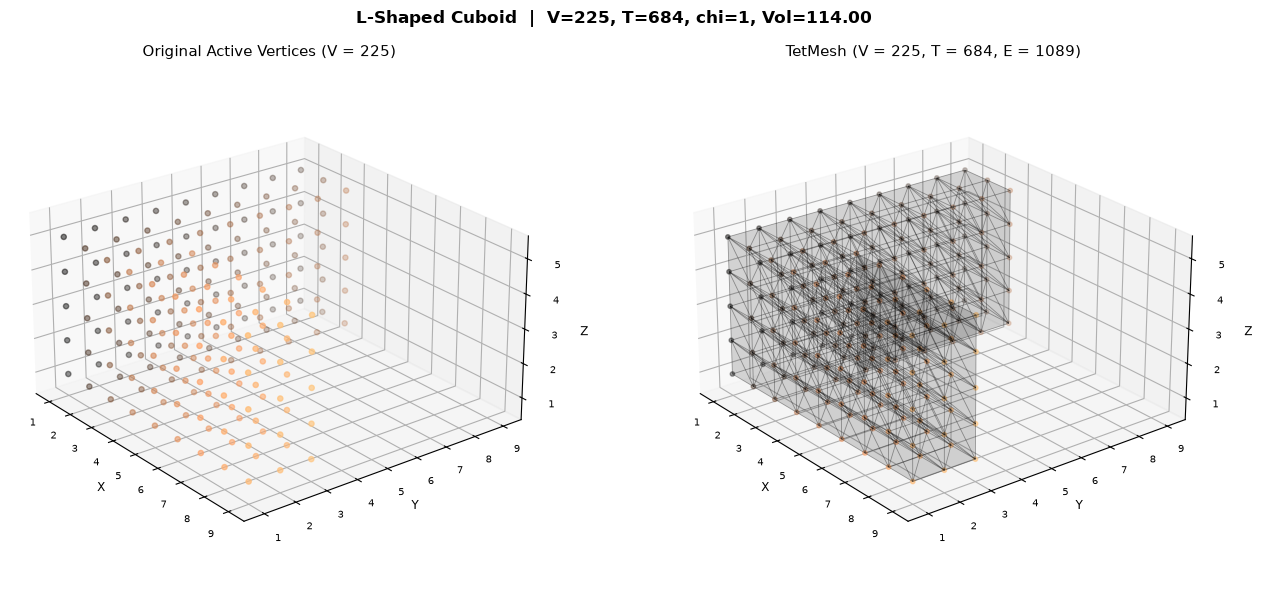

In [5]:
title = 'L-Shaped Cuboid'

mask = np.zeros((11, 11, 7), dtype=bool)
mask[1:10, 1:4, 1:6] = True
mask[1:4, 1:10, 1:6] = True

mesh = validate_and_plot_tetmesh(mask, title=title)


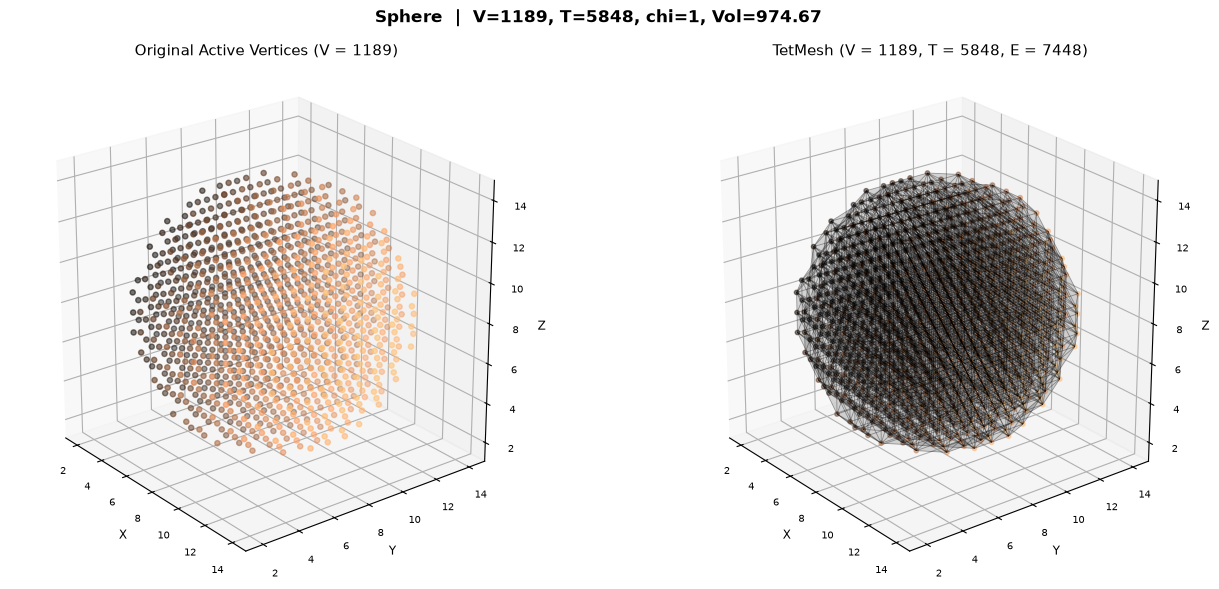

In [6]:
title = 'Sphere'

xg, yg, zg = np.ogrid[-8:9, -8:9, -8:9]
mask = (xg**2 + yg**2 + zg**2) <= 6.5**2

mesh = validate_and_plot_tetmesh(mask, title=title)


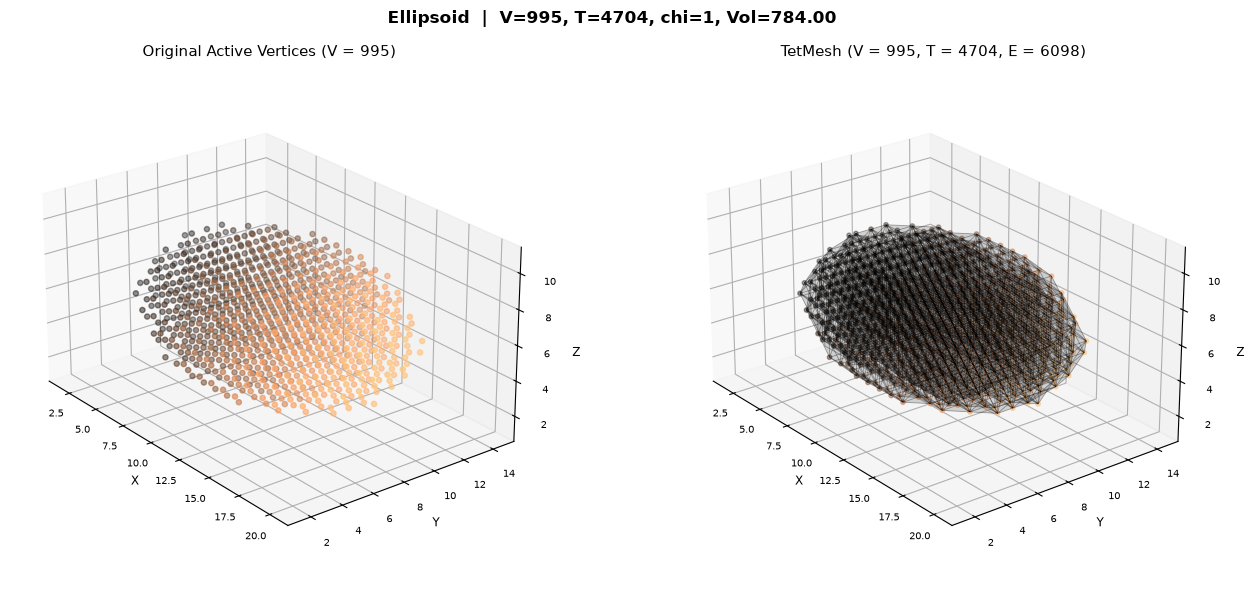

In [7]:
title = 'Ellipsoid'

xe, ye, ze = np.ogrid[-11:12, -8:9, -6:7]
mask = ((xe / 9.2) ** 2 + (ye / 6.2) ** 2 + (ze / 4.2) ** 2) <= 1.0

mesh = validate_and_plot_tetmesh(mask, title=title)


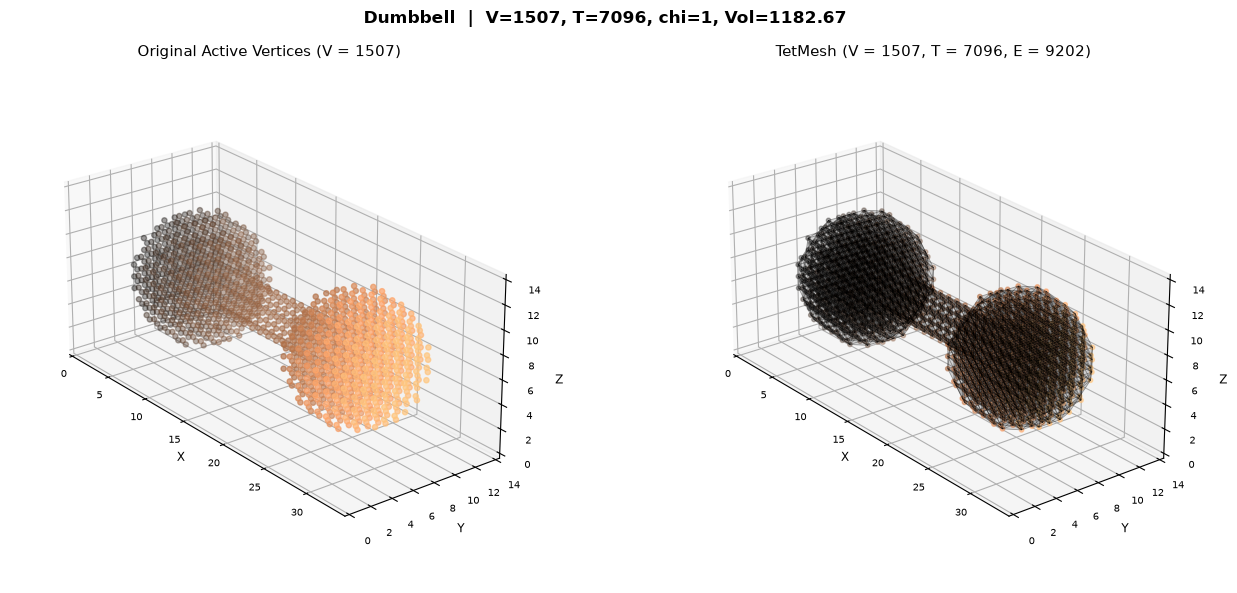

In [ ]:
title = 'Dumbbell'

def make_dumbbell_mask(
    bell_radius: float = 5.5,
    neck_radius: float = 2.0,
    neck_half_length: float = 6.0,
    pad: int = 1,
) -> NDArray[np.bool_]:
    """
    Construct a well-conditioned 3D binary dumbbell mask aligned along the X axis
    (two spherical bells joined by a cylindrical neck).
    """
    bell_offset = neck_half_length + 0.65 * bell_radius
    rx = int(np.ceil(bell_offset + bell_radius)) + pad
    ryz = int(np.ceil(bell_radius)) + pad

    x, y, z = np.ogrid[-rx : rx + 1, -ryz : ryz + 1, -ryz : ryz + 1]
    r_yz2 = y**2 + z**2

    left_bell = ((x + bell_offset) ** 2 + r_yz2) <= bell_radius**2
    right_bell = ((x - bell_offset) ** 2 + r_yz2) <= bell_radius**2
    neck = (np.abs(x) <= bell_offset) & (r_yz2 <= neck_radius**2)

    mask = left_bell | right_bell | neck
    return np.asarray(mask, dtype=bool)

mask = make_dumbbell_mask()
mesh = validate_and_plot_tetmesh(mask, title=title)

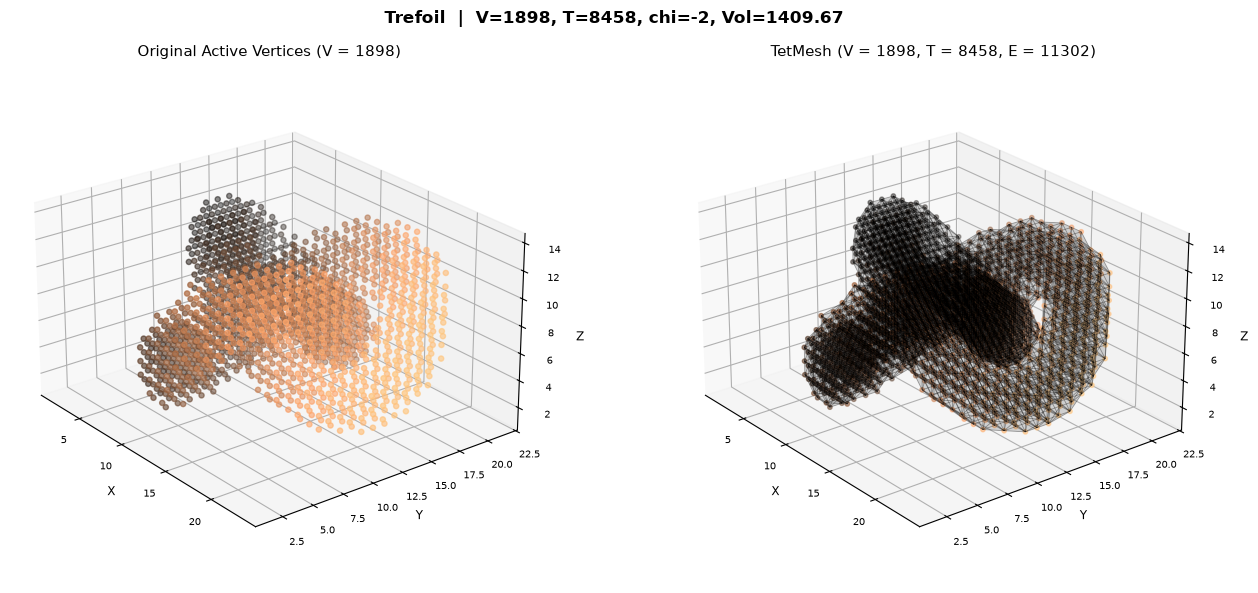

In [9]:
title = 'Trefoil'

t_param = np.linspace(0.0, 2.0 * np.pi, 600, endpoint=False)
knot_centerline = np.column_stack(
    [
        np.sin(t_param) + 2.0 * np.sin(2.0 * t_param),
        np.cos(t_param) - 2.0 * np.cos(2.0 * t_param),
        -np.sin(3.0 * t_param),
    ]
)

kx, ky, kz = np.meshgrid(
    np.linspace(-4.2, 4.2, 26),
    np.linspace(-4.2, 4.2, 26),
    np.linspace(-2.2, 2.2, 16),
    indexing="ij",
)
grid_pts = np.column_stack([kx.ravel(), ky.ravel(), kz.ravel()])
min_dist = np.min(
    np.linalg.norm(grid_pts[:, None, :] - knot_centerline[None, :, :], axis=-1),
    axis=1,
)

mask = (min_dist <= 0.85).reshape(kx.shape)

mesh = validate_and_plot_tetmesh(mask, title=title)


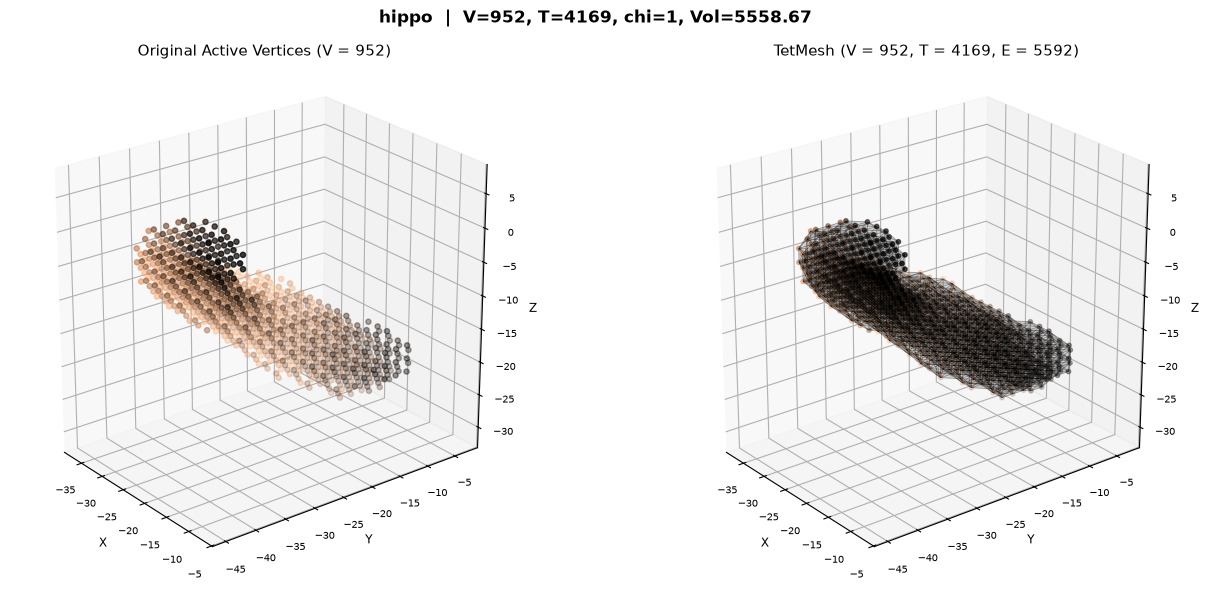

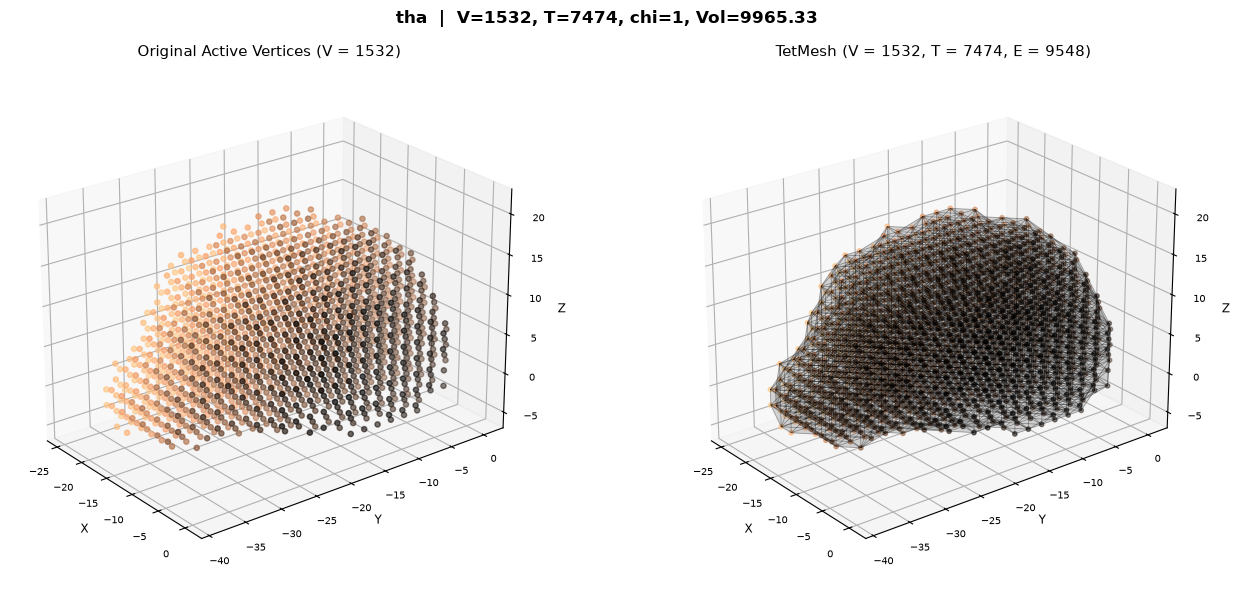

In [10]:
for struct in ['hippo', 'tha']: 
    nifti = Nifti1Image.load(f'../tutorials/tutorial_data/hcp_{struct}-lh_thr25.nii.gz')
    validate_and_plot_tetmesh(nifti.get_fdata().astype(bool), struct, nifti.affine)

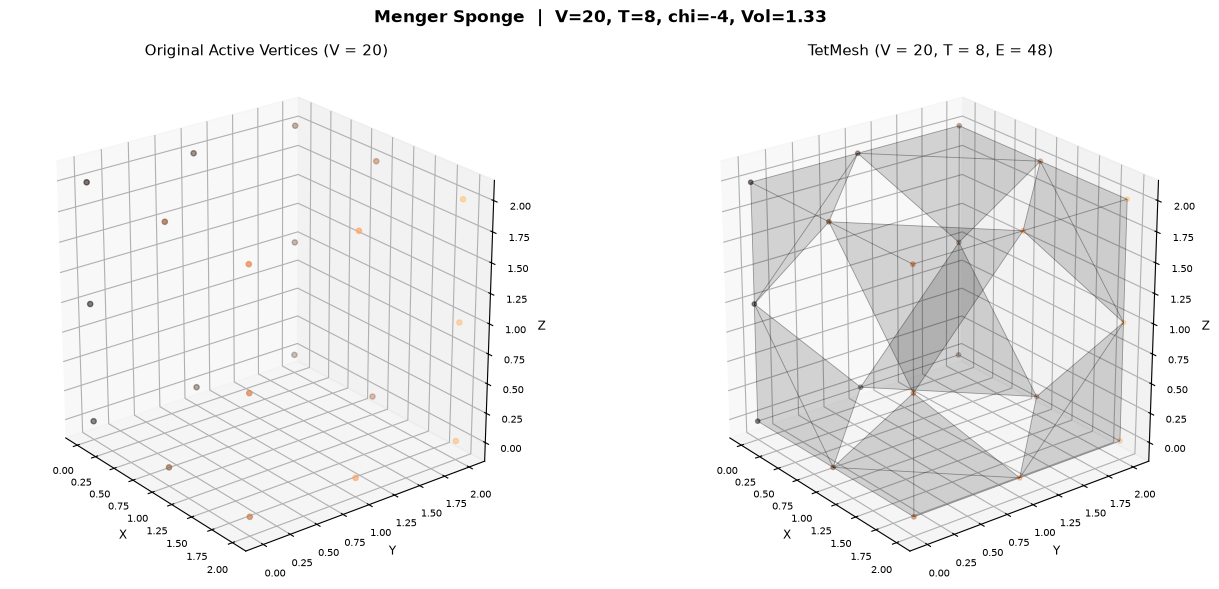

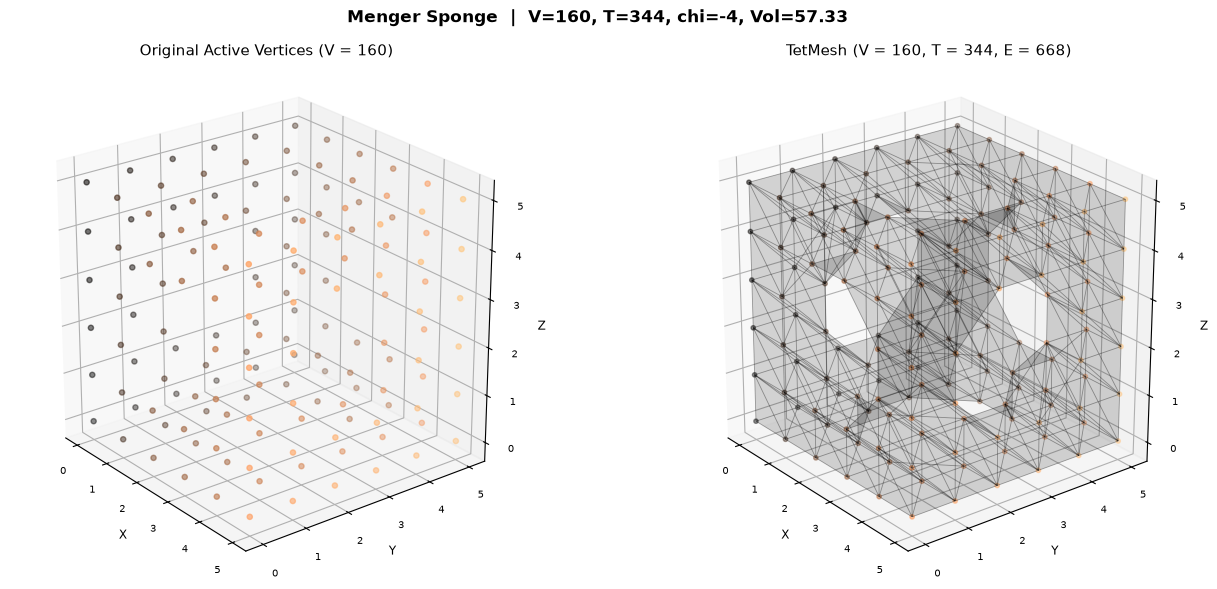

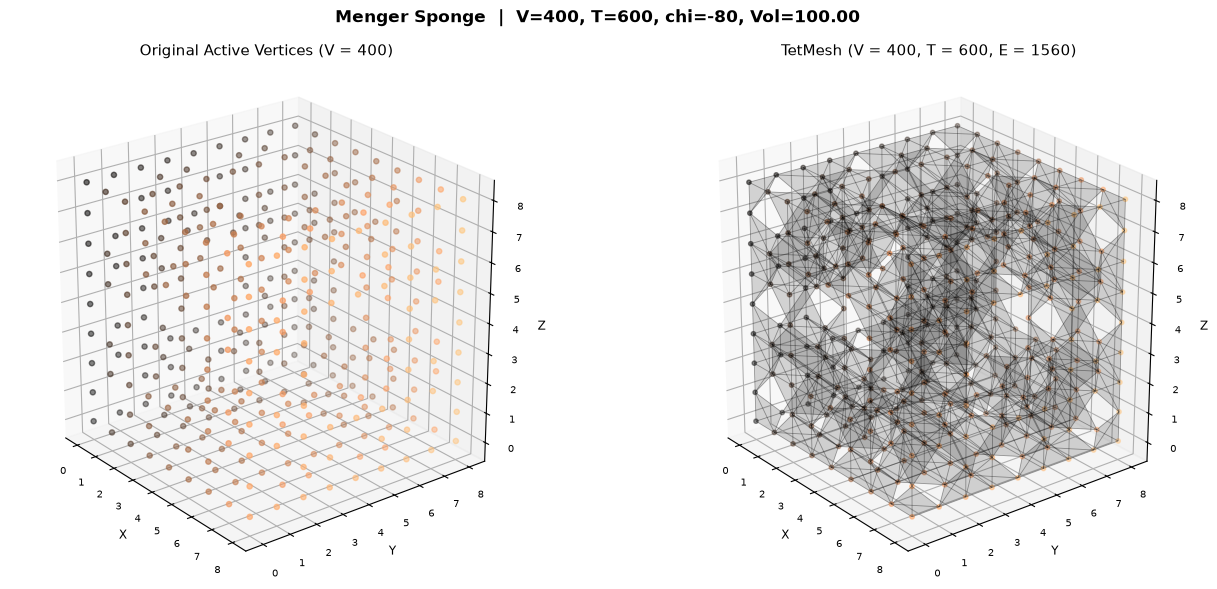

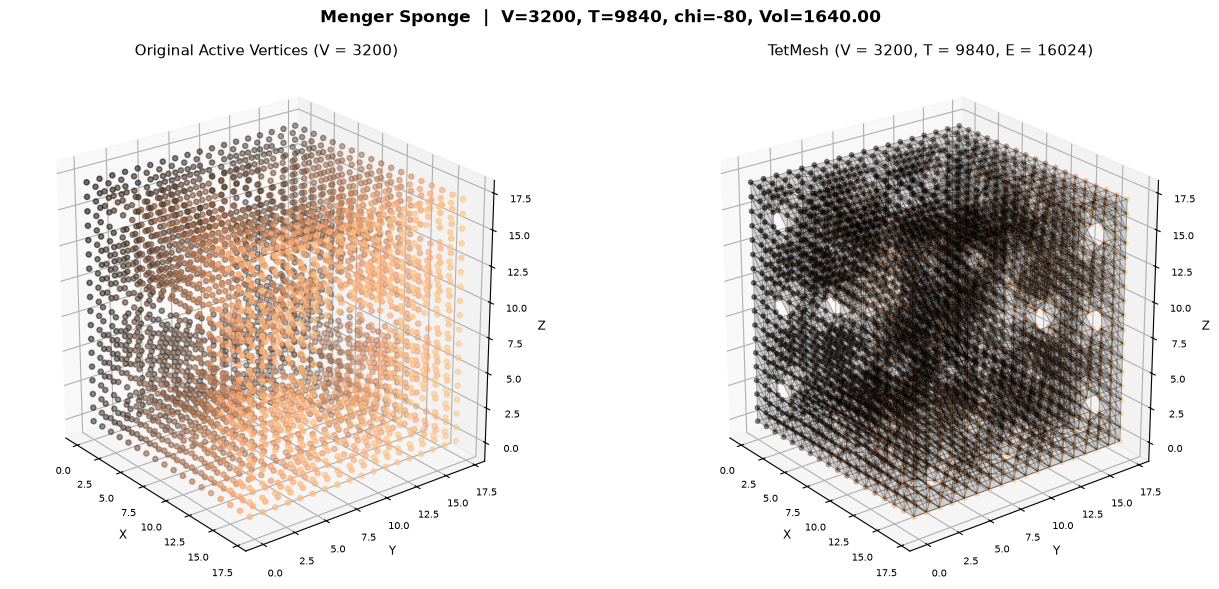

In [11]:
title = 'Menger Sponge'

def make_menger_sponge(depth: int = 3, length: int = 1) -> NDArray[np.bool_]:
    """Construct a 3D Menger sponge binary mask of 3**depth * length."""
    n = 3 ** depth * length
    sponge = np.ones((n, n, n), dtype=bool)
    for d in range(depth):
        step = 3 ** d
        mid = ((np.arange(n) // length) // step) % 3 == 1
        all_idx = np.ones(n, dtype=bool)
        sponge[np.ix_(mid, mid, all_idx)] = False
        sponge[np.ix_(mid, all_idx, mid)] = False
        sponge[np.ix_(all_idx, mid, mid)] = False
    return sponge

for depth in [1, 2]:
    for length in [1, 2]:
        mask = make_menger_sponge(depth=depth, length=length)
        mesh = validate_and_plot_tetmesh(mask, title=title)